# CS117 · A/B/C feature and matching demo

A: SIFT + ratio test. B: SIFT + LightGlue. C: SuperPoint + LightGlue. All three use the same model, feature-location, matching and geometry interfaces.

This notebook uses two **train** examples and displays images inline only. It does not save demo images or run the full benchmark. The final two sections read per-method train and test CSVs and plot the full-split comparisons. Install `requirements.txt` first; C may download pretrained weights on its first use.


## 0. Prepare Colab, dependencies, and device

Run these cells in order. On Colab, the first cell clones the project into `/content`, or mounts your existing Google Drive project when `USE_GOOGLE_DRIVE = True`. The GitHub copy must include your latest scripts and split files; local edits are not automatically uploaded. Existing project folders are reused without pulling or overwriting changes. On a local computer, it uses the current project folder.

The pinned LightGlue repository is fetched if missing. The dataset is obtained later through `dataset_load.get_data_root()`. Saved test CSVs are displayed only if present in the selected project folder. Nothing here launches train.py or the full test evaluation.


In [35]:
from pathlib import Path
import importlib.util
import json
import os
import subprocess
import sys

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

REPO_URL = "https://github.com/StevenZBX/CS-117-Final-Project.git"
USE_GOOGLE_DRIVE = False  # True: use a project folder already copied to Google Drive.
DRIVE_PROJECT = "/content/drive/MyDrive/CS-117-Final-Project"

if IN_COLAB:
    if USE_GOOGLE_DRIVE:
        from google.colab import drive
        drive.mount("/content/drive")
        PROJECT_ROOT = Path(DRIVE_PROJECT)
    else:
        PROJECT_ROOT = Path("/content/CS-117-Final-Project")
        if not PROJECT_ROOT.exists():
            subprocess.check_call(["git", "clone", REPO_URL, str(PROJECT_ROOT)])
else:
    PROJECT_ROOT = Path.cwd()  # Set explicitly if starting outside the project.
    if not (PROJECT_ROOT / "scripts/method_A.py").is_file():
        PROJECT_ROOT = next((parent for parent in PROJECT_ROOT.parents
                             if (parent / "scripts/method_A.py").is_file()), PROJECT_ROOT)

required_files = ["scripts/method_A.py", "scripts/method_B.py", "scripts/method_C.py",
                  "scripts/evaluate.py", "scripts/dataset_load.py", "configs/experiment.json",
                  "splits/hpatches_train.txt", "splits/hpatches_test.txt", "requirements.txt",
                  "third_party_versions.json"]
missing_files = [name for name in required_files if not (PROJECT_ROOT / name).is_file()]
if missing_files:
    raise FileNotFoundError(f"Project folder is missing {missing_files}. Use the latest project copy or update REPO_URL/PROJECT_ROOT.")
os.chdir(PROJECT_ROOT)
print("Environment:", "Google Colab" if IN_COLAB else "Local notebook")
print("Project:", PROJECT_ROOT)
print("Notebook Python:", sys.executable)

# third_party/ is excluded from the project Git repository. Fetch the recorded
# LightGlue revision before installing the editable dependency in requirements.txt.
lightglue_spec = json.loads((PROJECT_ROOT / "third_party_versions.json").read_text())["LightGlue"]
lightglue_dir = PROJECT_ROOT / lightglue_spec["path"]
if not lightglue_dir.exists():
    lightglue_dir.parent.mkdir(parents=True, exist_ok=True)
    subprocess.check_call(["git", "clone", lightglue_spec["url"], str(lightglue_dir)])
    subprocess.check_call(["git", "-C", str(lightglue_dir), "checkout", lightglue_spec["commit"]])
if not (lightglue_dir / "lightglue/__init__.py").is_file():
    raise FileNotFoundError(f"Incomplete LightGlue checkout: {lightglue_dir}")


Environment: Local notebook
Project: /Users/zbx/Desktop/CS-117-Final-Project
Notebook Python: /Users/zbx/Desktop/CS-117-Final-Project/.venv-a/bin/python


### Install missing dependencies

Installation targets the current notebook kernel. If packages are installed, restart the kernel/session and run from the top again before detecting the device.


In [36]:
required = ["numpy", "cv2", "matplotlib", "torch", "torchvision", "kornia", "lightglue", "kagglehub"]
missing = [name for name in required if importlib.util.find_spec(name) is None]
if missing:
    print("Installing dependencies into this notebook environment:", ", ".join(missing))
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "-r", str(PROJECT_ROOT / "requirements.txt")],
        cwd=str(PROJECT_ROOT),
    )
    raise RuntimeError("Dependencies installed. Restart the notebook kernel/session, then Run All again.")
print("Dependency check passed.")


Dependency check passed.


### Automatically detect the device

Priority: **CUDA → MPS → CPU**. The resulting `DEVICE` is reused by the setup and all demo matching calls. CPU is selected only when neither accelerator is available.


In [37]:
import torch

mps_backend = getattr(torch.backends, "mps", None)
if torch.cuda.is_available():
    DEVICE = "cuda"
elif mps_backend is not None and mps_backend.is_available():
    DEVICE = "mps"
else:
    DEVICE = "cpu"

print(f"Selected device: {DEVICE}")
print("A and SIFT extraction use CPU; B/C learned matching uses the selected device.")
if IN_COLAB and DEVICE == "cpu":
    print("No GPU is available in this Colab session. The demo will use CPU.")


Selected device: mps
A and SIFT extraction use CPU; B/C learned matching uses the selected device.


## 1. Shared setup

Choose `METHODS = ["A", "B", "C"]` or any subset. `DEVICE` comes from the automatic detection above. The shared experiment configuration controls image resizing and feature extraction. This section selects two train examples; it does not run parameter search or the full test benchmark.


In [38]:
from pathlib import Path
import json
import sys
import numpy as np
import cv2
from IPython import get_ipython
from IPython.display import Image, display

if not (PROJECT_ROOT / "scripts/method_A.py").is_file():
    raise FileNotFoundError("Set PROJECT_ROOT to the folder containing scripts/ and data/.")
sys.path.insert(0, str(PROJECT_ROOT / "scripts"))
from evaluate import build_backends, match_points
from dataset_load import get_data_root, load_image, score, validate_splits
from evaluate import LABELS

get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt

METHODS = ["A", "B", "C"]
CONFIG = json.loads((PROJECT_ROOT / "configs/experiment.json").read_text())
DATA = get_data_root()
RESULTS = PROJECT_ROOT / "results"
cv2.setNumThreads(CONFIG["opencv_threads"])
cv2.setRNGSeed(0)
train_ids, _ = validate_splits(DATA, "train")
SEQUENCES = [next(s for s in train_ids if s.startswith("i_")),
             next(s for s in train_ids if s.startswith("v_"))]
TARGET_INDEX = 5
DISPLAY_LIMIT = 150
assert all(s in train_ids for s in SEQUENCES)
assert TARGET_INDEX in range(2, 7)
backends = build_backends(METHODS, CONFIG, PROJECT_ROOT / "data/feature_cache", DEVICE)
print("Train examples:", ", ".join(SEQUENCES))
print("Methods:", ", ".join(f"{m}: {LABELS[m]} ({backends[m][3]})" for m in backends))

Train examples: i_ajuntament, v_abstract
Methods: A: SIFT + ratio test (cpu), B: SIFT + LightGlue (mps), C: SuperPoint + LightGlue (mps)


## 2. Feature extraction on real images

Each method exposes `extract_keypoints(extractor, image, device)`, returning an `(N, 2)` NumPy array in input-image pixels. Cyan dots show a display subset, while titles report the full count. Feature ordering differs between detectors; these dots do not represent correspondences.


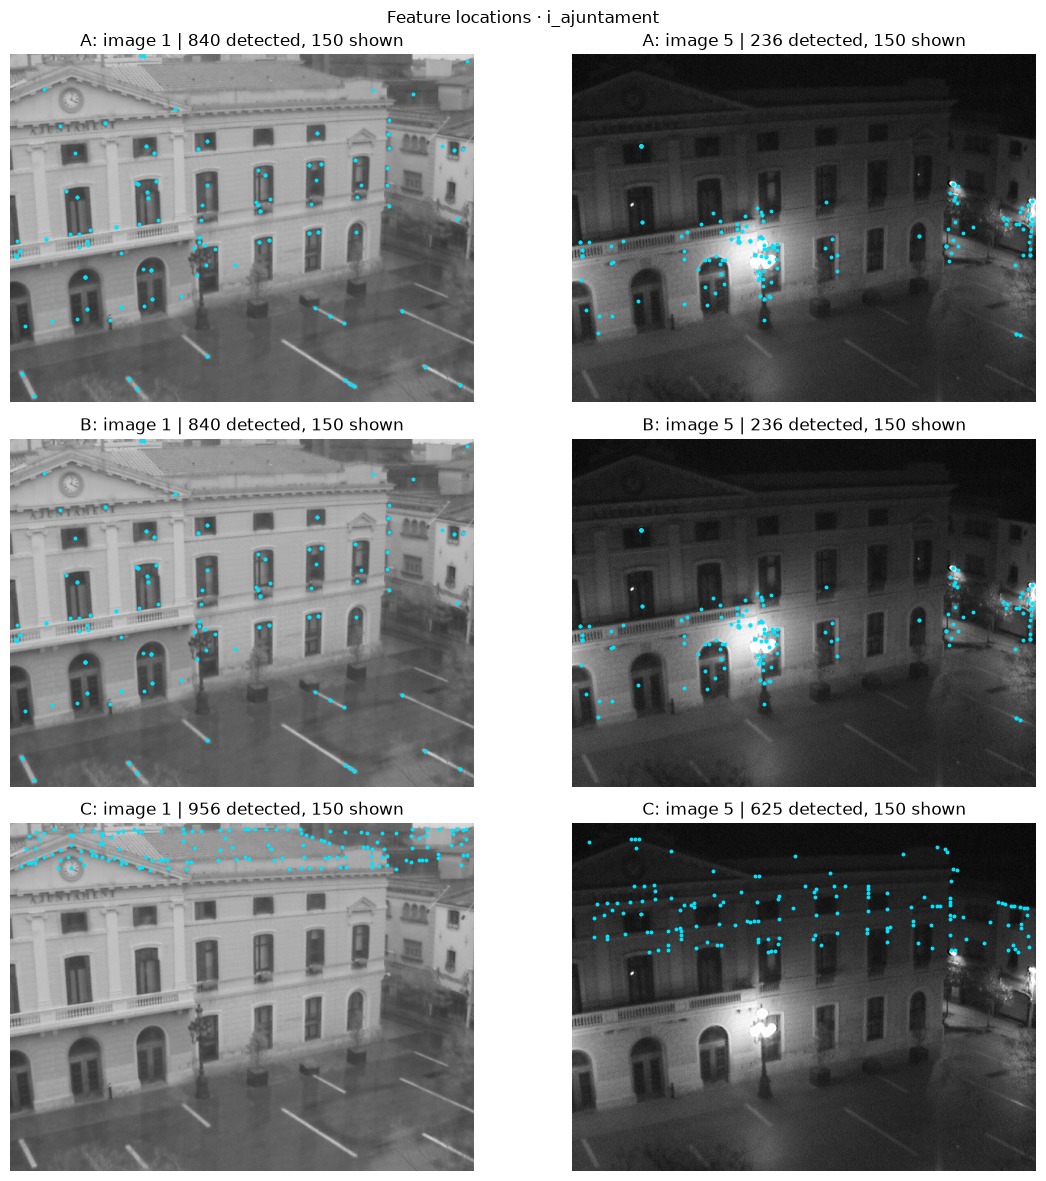

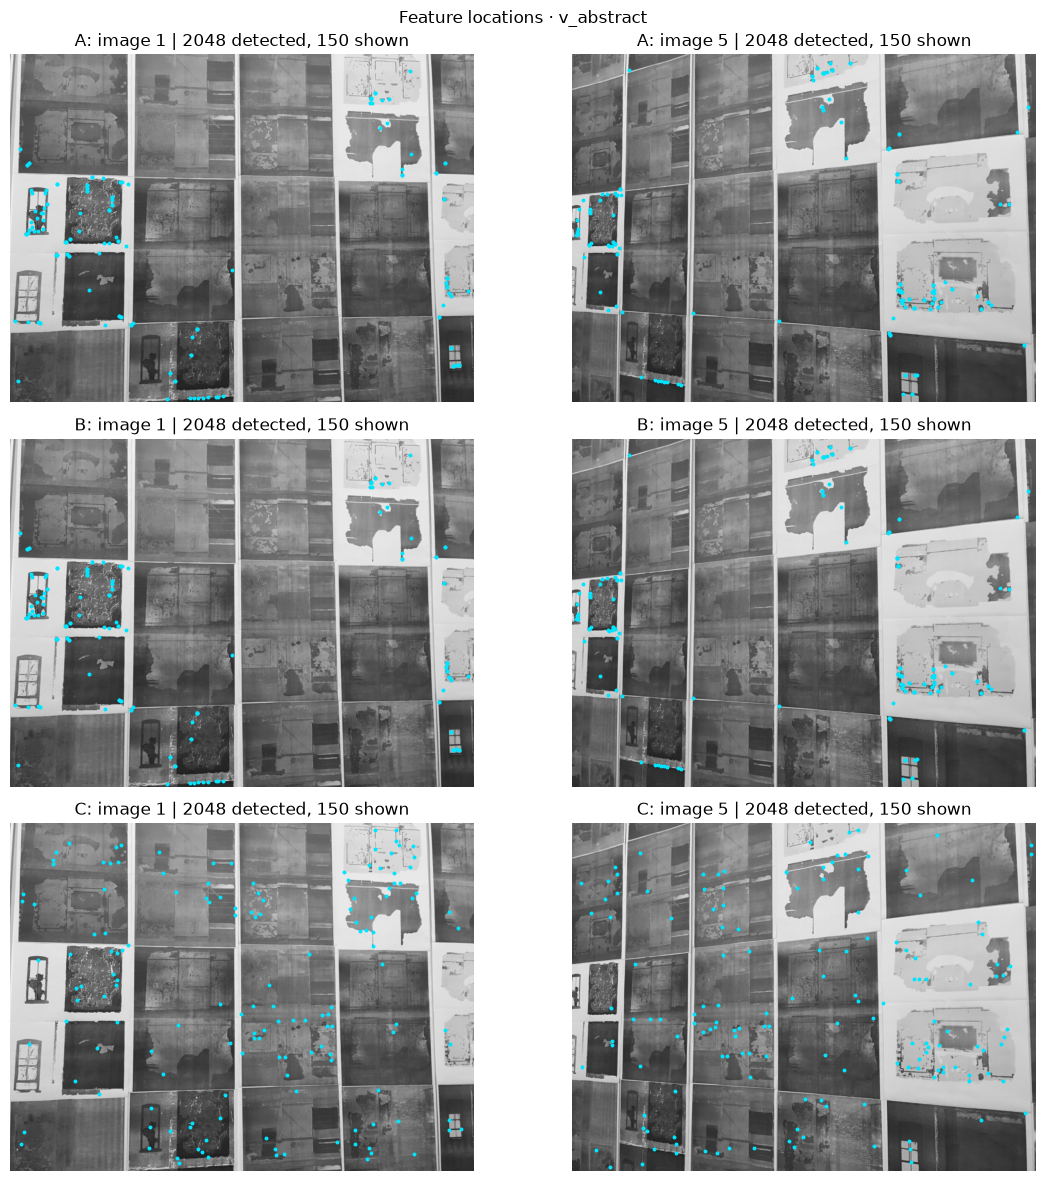

In [39]:
examples = {}
for sequence in SEQUENCES:
    for index in (1, TARGET_INDEX):
        examples[sequence, index] = load_image(DATA / sequence / f"{index}.ppm", CONFIG["max_side"])

for sequence in SEQUENCES:
    fig, axes = plt.subplots(len(backends), 2, figsize=(12, 4 * len(backends)), squeeze=False)
    for row, (name, (module, extractor, matcher, device)) in enumerate(backends.items()):
        for col, index in enumerate((1, TARGET_INDEX)):
            image, _ = examples[sequence, index]
            points = module.extract_keypoints(extractor, image, device)
            shown = points[:DISPLAY_LIMIT]
            ax = axes[row, col]
            ax.imshow(image, cmap="gray", vmin=0, vmax=255)
            ax.scatter(shown[:, 0], shown[:, 1], s=8, c="#00e5ff", linewidths=0)
            ax.set_title(f"{name}: image {index} | {len(points)} detected, {len(shown)} shown")
            ax.axis("off")
    fig.suptitle(f"Feature locations · {sequence}")
    fig.tight_layout()
    display(fig)
    plt.close(fig)


## 3. Matching through the same interface

`match(extractor, matcher, img1, imgk, device)` returns two corresponding `(N, 2)` point arrays. The shared runner validates this output. Ground-truth geometry is transformed as `H_resized = S1 @ H @ inv(S0)`.

Green lines have forward reprojection error **< 3 resized pixels**; red lines fail this threshold. A display subset is drawn, but the title's MMA@3 uses every returned match. Zero-match pairs score zero. These examples illustrate behavior and are not aggregate benchmark results.


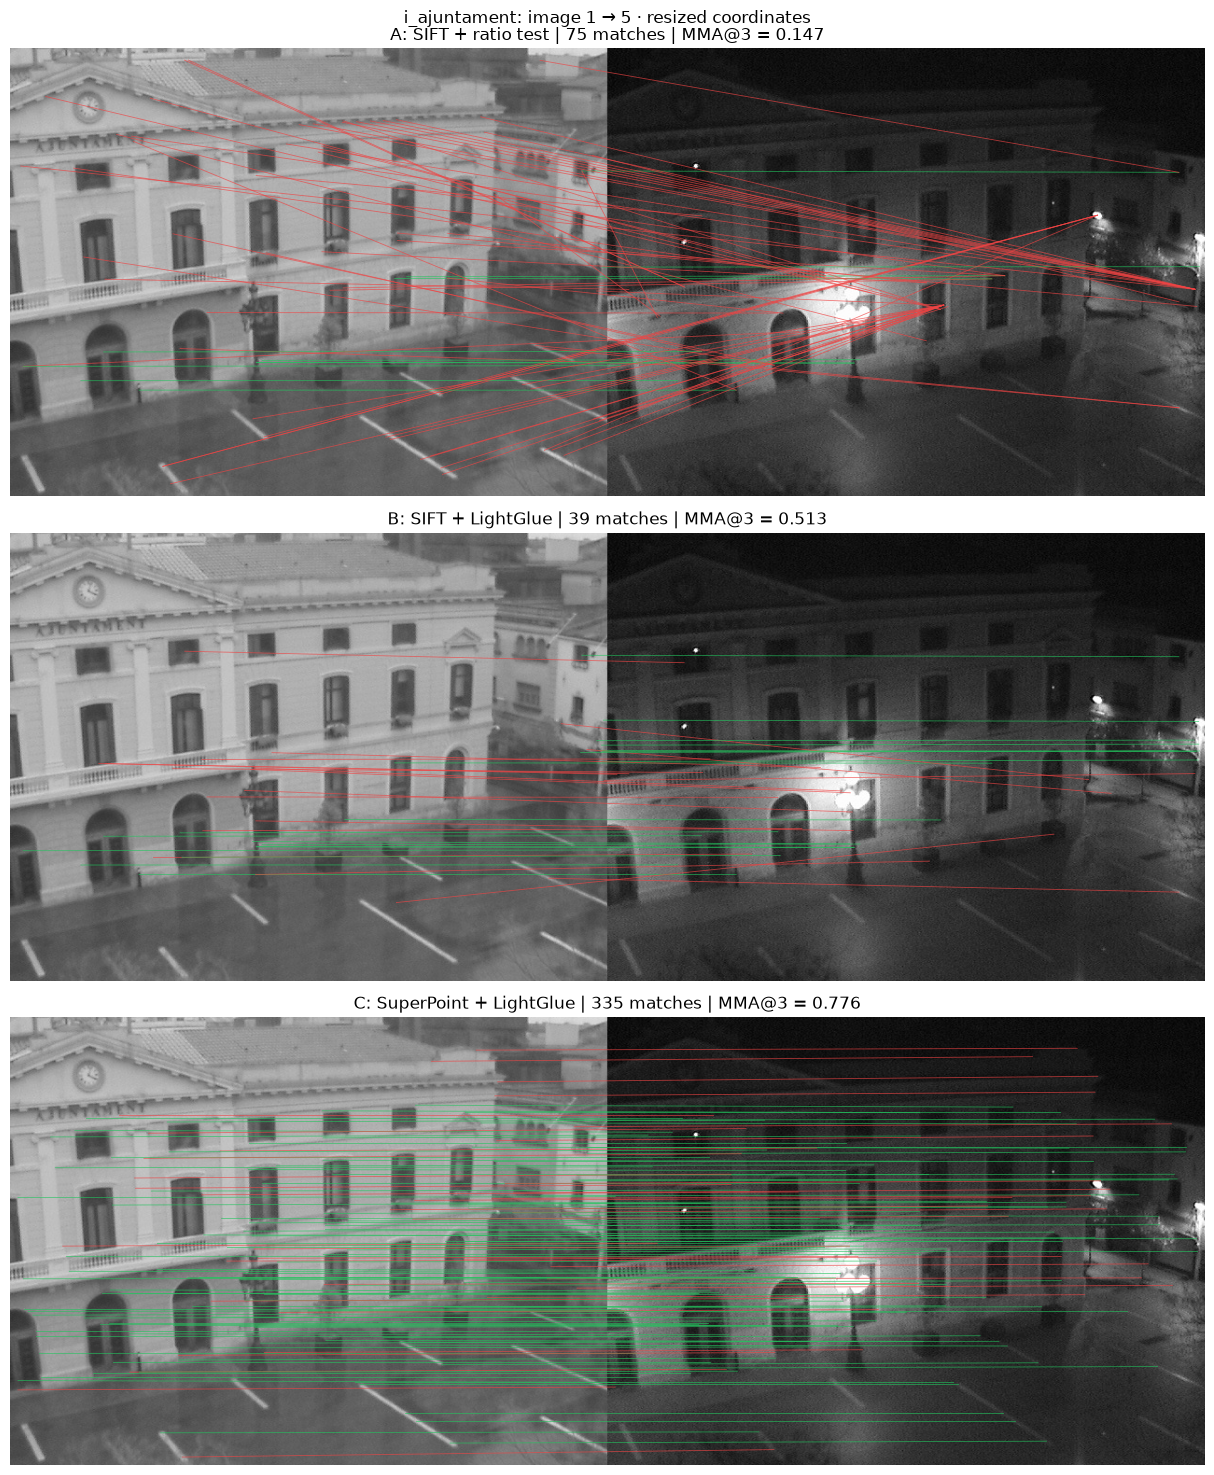

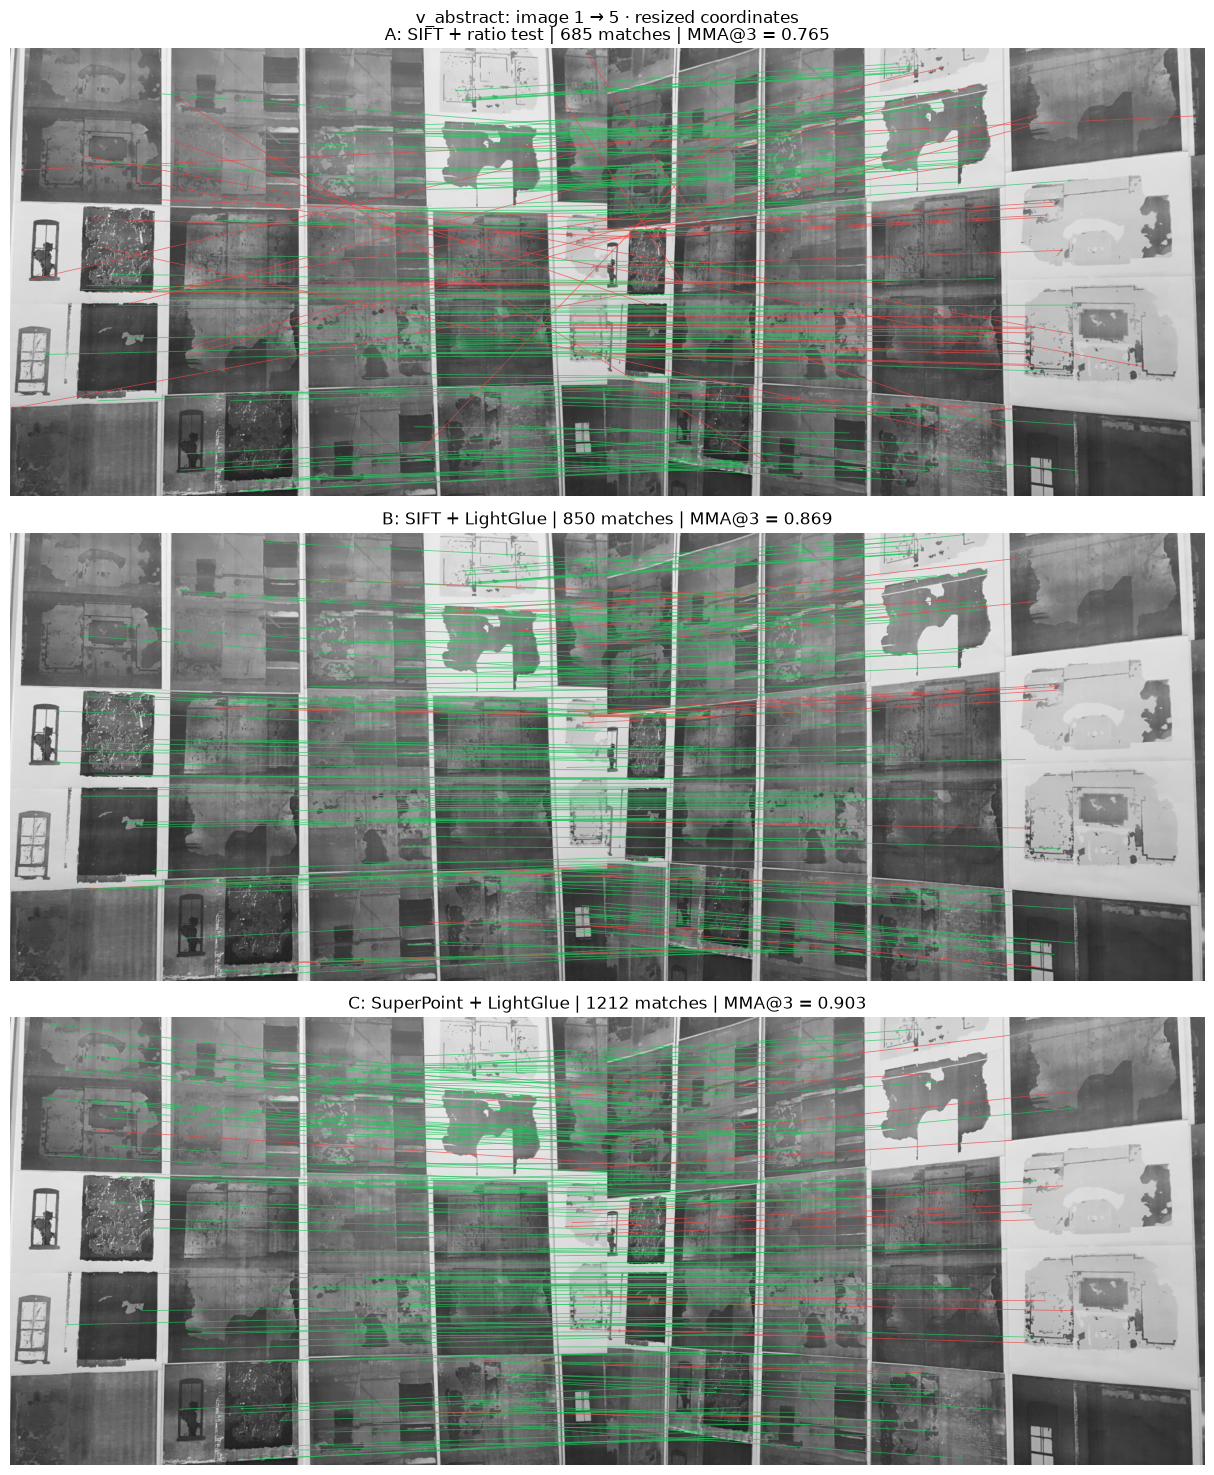

In [40]:
for sequence in SEQUENCES:
    image0, S0 = examples[sequence, 1]
    image1, S1 = examples[sequence, TARGET_INDEX]
    H = np.loadtxt(DATA / sequence / f"H_1_{TARGET_INDEX}")
    H_resized = S1 @ H @ np.linalg.inv(S0)
    height = max(image0.shape[0], image1.shape[0])
    offset = image0.shape[1]
    canvas = np.zeros((height, offset + image1.shape[1]), dtype=np.uint8)
    canvas[:image0.shape[0], :offset] = image0
    canvas[:image1.shape[0], offset:] = image1
    fig, axes = plt.subplots(len(backends), 1, figsize=(14, 5 * len(backends)), squeeze=False)
    for ax, (name, backend) in zip(axes[:, 0], backends.items()):
        p0, p1 = match_points(backend, image0, image1)
        err = backend[0].reprojection_error(p0, p1, H_resized)
        ax.imshow(canvas, cmap="gray", vmin=0, vmax=255)
        shown = np.linspace(0, len(p0) - 1, min(DISPLAY_LIMIT, len(p0)), dtype=int)
        for i in shown:
            color = "#22c55e" if err[i] < 3 else "#ef4444"
            ax.plot([p0[i, 0], p1[i, 0] + offset], [p0[i, 1], p1[i, 1]],
                    color=color, linewidth=0.6, alpha=0.7)
        ax.set_title(f"{name}: {LABELS[name]} | {len(p0)} matches | MMA@3 = {score(err, 3):.3f}")
        ax.axis("off")
    fig.suptitle(f"{sequence}: image 1 → {TARGET_INDEX} · resized coordinates")
    fig.tight_layout()
    display(fig)
    plt.close(fig)

for _, extractor, _, _ in backends.values():
    if hasattr(extractor, "clear_memory"):
        extractor.clear_memory()


## 4. A/B/C comparison on the full train results

Read `results/train_A.csv`, `results/train_B.csv`, and `results/train_C.csv`, generated by `python scripts/train.py`. Each file contains the selected best candidate's **480 pairs from all 96 train sequences** (47 illumination, 49 viewpoint). These are parameter-selection results on train, not held-out test performance.

The shared `evaluate.plot_results()` interface displays MMA@3 by target image index, MMA across 1–10 pixel thresholds, and mean returned match counts. Illumination and viewpoint appear separately. Each pair contributes equally; zero-match pairs score zero.

This section only reads CSVs and plots inline. It does not reuse the two demo-pair scores, rerun inference, or save image files. Missing or outdated split results are reported and skipped; partial method availability is explicitly identified.


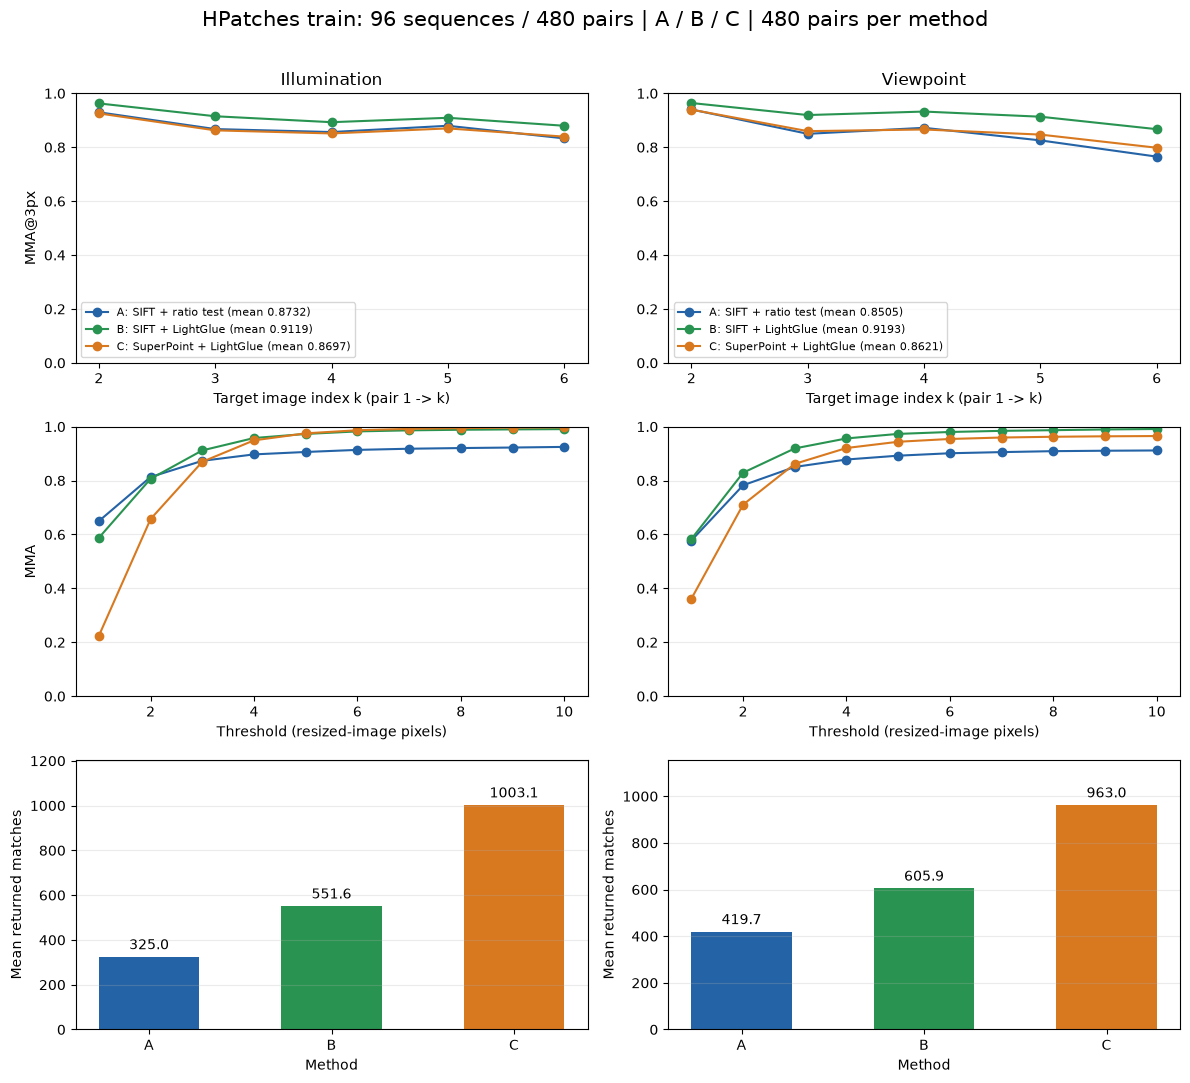

In [41]:
from evaluate import read_results, plot_results, validate_results

train_ids, _ = validate_splits(DATA, "train")
expected_train_pairs = {(sequence, k) for sequence in train_ids for k in range(2, 7)}
train_results = {}
for method in METHODS:
    path = RESULTS / f"train_{method}.csv"
    if not path.is_file():
        print(f"Missing {path.name}; run python scripts/train.py --methods {method} separately.")
        continue
    rows = read_results(path)
    if len(rows) != len(expected_train_pairs) or {(row["sequence"], row["k"]) for row in rows} != expected_train_pairs:
        print(f"Skipping {path.name}: expected the current 96 train sequences / 480 pairs.")
        continue
    validate_results({method: rows})
    train_results[method] = rows
if train_results:
    fig = plot_results(train_results, split="train: 96 sequences / 480 pairs")
    display(fig)
    plt.close(fig)
if len(train_results) != len(METHODS):
    print("The full train comparison needs current train CSVs for all selected methods.")


## 5. Current test comparison

The new test contains 20 sequences / 100 pairs. This section reads existing CSVs and never runs evaluation. Old test CSVs with 480 pairs are skipped until you rerun evaluation on the new split. Figures display inline only.


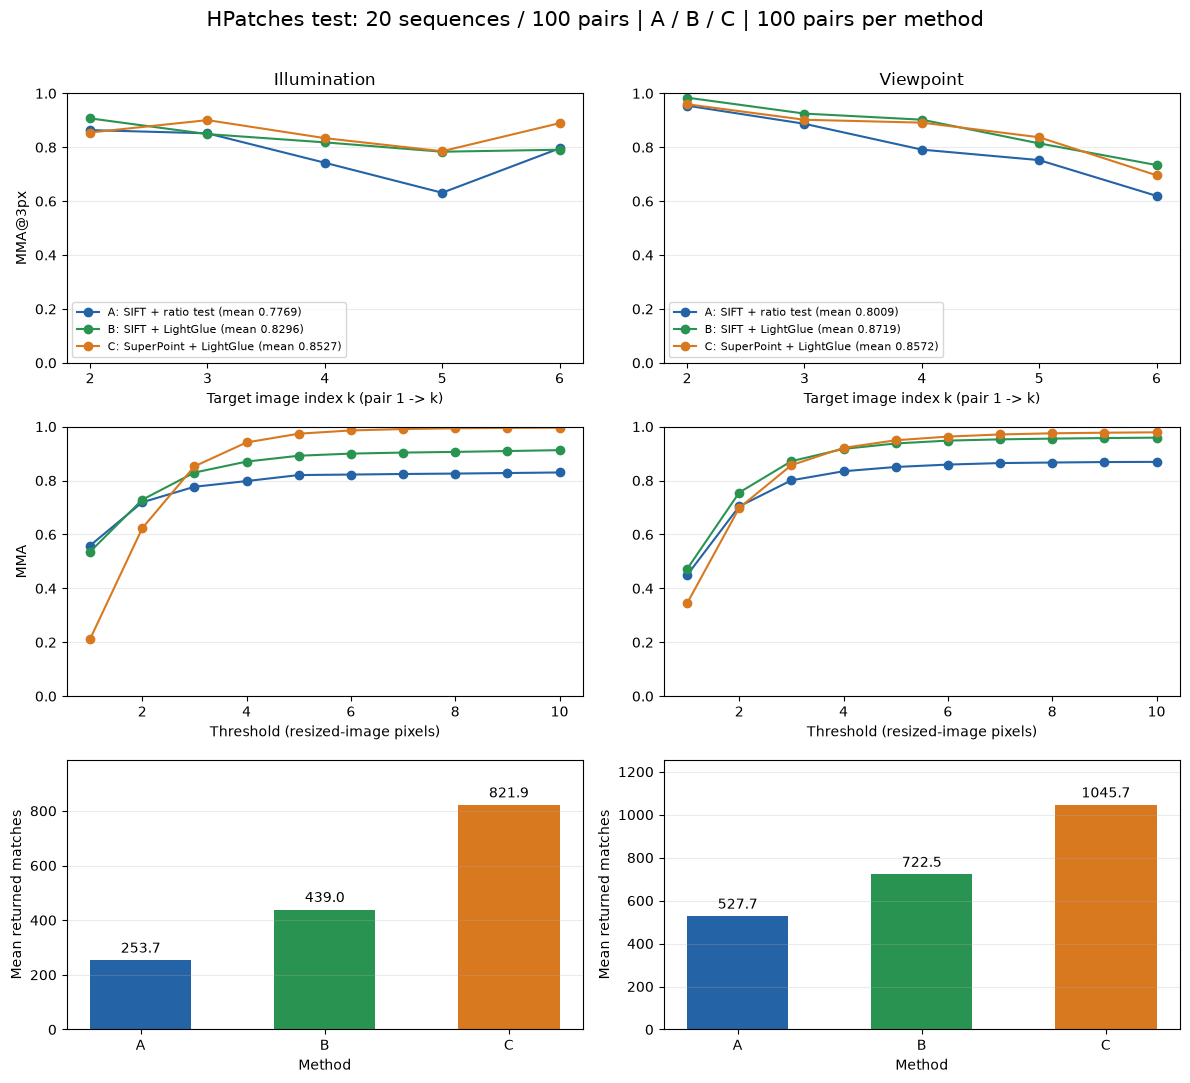

In [42]:
from evaluate import read_results, plot_results

test_ids, _ = validate_splits(DATA, "test")
expected = {(sequence, k) for sequence in test_ids for k in range(2, 7)}
formal_results = {}
for method in METHODS:
    path = RESULTS / f"test_{method}.csv"
    if not path.is_file():
        print(f"Missing {path.name}; run evaluation separately.")
        continue
    rows = read_results(path)
    if len(rows) != 100 or {(row["sequence"], row["k"]) for row in rows} != expected:
        print(f"Skipping {path.name}: not the current 20-sequence test. Rerun python scripts/evaluate.py.")
        continue
    formal_results[method] = rows
if formal_results:
    fig = plot_results(formal_results, split="test: 20 sequences / 100 pairs")
    display(fig)
    plt.close(fig)
if len(formal_results) != len(METHODS):
    print("The full comparison needs current test CSVs for all selected methods.")
